# Paper 05: Deep Residual Learning for Image Recognition (ResNet)
**Authors**: Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun (2015)

---

## 1. The Historical Breaking Point: The Degradation Problem
With Kaiming Initialization (Paper #1) and Batch Normalization (Paper #3), researchers could train 20-layer networks without vanishing gradients.
However, when they stacked more layers (creating 56-layer plain networks), an unexpected catastrophe struck:
- **Plain-56 had higher training error than Plain-20** (it was *not* overfitting!).
- Stacked non-linear layers struggled to learn even the simple **identity mapping** $H(x) = x$.

## 2. The First-Principles Solution: Residual Learning
Instead of forcing layers to fit $H(x)$ directly, reformulate the task to fit a **residual mapping**:
$$F(x) := H(x) - x \implies H(x) = F(x) + x$$

- If identity is optimal, it is infinitely easier for gradient descent to drive residual weights to zero: $F(x) \to 0$.
- **The Gradient Highway**: By the chain rule, $\frac{\partial \mathcal{L}}{\partial x} = \frac{\partial \mathcal{L}}{\partial y} \frac{\partial F(x)}{\partial x} + \frac{\partial \mathcal{L}}{\partial y}$.
  The unobstructed $+1$ term lets gradients flow directly to the shallowest stem layers across 100+ layers without vanishing!

In this notebook, you will test `BasicBlock`, `Bottleneck`, and the full `ResNet` family implemented in `model.py`.

---
## Setup
`%autoreload 2` ensures any modifications in `model.py` are immediately available.

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from model import BasicBlock, Bottleneck, ResNet, resnet18, resnet50
from core.optimizers import AdamW
import tests

---
## Part 1: BasicBlock & Bottleneck Verification

We verify:
1. `BasicBlock`: Stride 1 (identity addition) and Stride 2 (spatial downsampling with projection shortcut).
2. `Bottleneck`: 3-layer $1\times 1 \to 3\times 3 \to 1\times 1$ compression and $4\times$ channel expansion.

In [15]:
print("Testing BasicBlock Shapes:")
tests.test_basic_block_shapes(BasicBlock)

print("\nTesting Bottleneck Shapes & 4x Expansion:")
tests.test_bottleneck_shapes(Bottleneck)

Testing BasicBlock Shapes:
  [PASS] BasicBlock preserves tensor shapes on stride=1 and downsamples on stride=2!

Testing Bottleneck Shapes & 4x Expansion:
  [PASS] Bottleneck correctly applies 1x1->3x3->1x1 compression and 4x channel expansion!


True

---
## Part 2: ResNet Full Architecture & Gradient Highway

We test:
1. End-to-end forward passes for `ResNet-18` and `ResNet-50`.
2. **Gradient Highway**: Verifying that backward gradients flow unimpeded to early stem layers without vanishing.
3. **Single-Batch Overfit Gate**: Rapid convergence to near-zero loss on a training batch.

In [17]:
print("Testing Full ResNet Architectures:")
tests.test_resnet_architectures(resnet18, resnet50)

print("\nTesting Residual Gradient Highway:")
tests.test_gradient_highway(resnet18)

print("\nTesting Single-Batch Overfit Gate:")
tests.test_single_batch_overfit(resnet18)

Testing Full ResNet Architectures:
  [PASS] ResNet-18 forward pass output shape matches (B, 1000)!
  [PASS] ResNet-50 forward pass output shape matches (B, 10)!

Testing Residual Gradient Highway:
  [PASS] Residual Gradient Highway active: stem conv1 received healthy grad norm 158.9480!

Testing Single-Batch Overfit Gate:
  [PASS] Single-batch overfit gate passed (loss dropped: 1.5046 -> 0.000081)!


True

---
## Part 3: The Degradation Experiment (PlainNet vs ResNet)

To reproduce Kaiming He's discovery, we train:
1. **Plain-20**: A 20-layer convolutional network *without* skip connections.
2. **ResNet-20**: A 20-layer convolutional network *with* residual shortcuts.

Both use the exact same layers, activations, Batch Normalization, and AdamW optimizer.

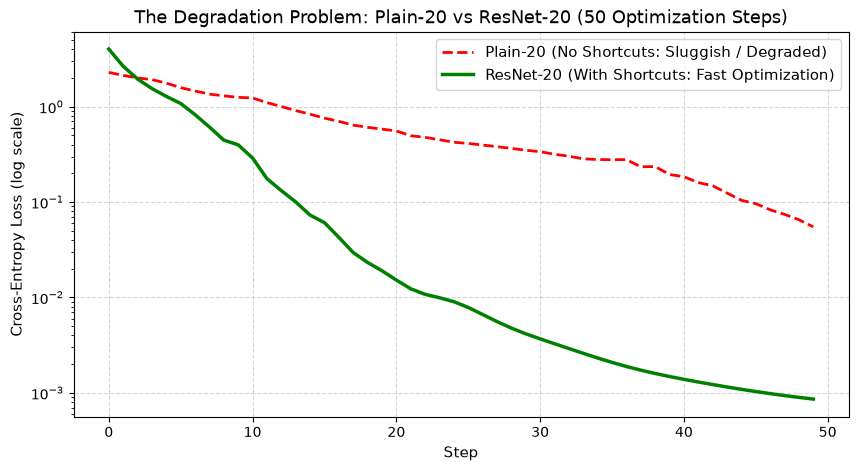

Final Loss -> Plain-20: 0.0549 | ResNet-20: 0.000861


In [18]:
torch.manual_seed(42)

# 1. Plain 20-layer Network (no residual connections)
class PlainBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

plain_net = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),
    *[PlainBlock(32) for _ in range(9)], # 1 + 18 = 19 convs
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(32, 10)
)

# 2. ResNet 20-layer Network (with skip connections)
class ResBlockSimple(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
    def forward(self, x):
        return self.relu(self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x))))) + x)

res_net = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),
    *[ResBlockSimple(32) for _ in range(9)],
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(32, 10)
)

# Synthetic Classification Batch
batch_x = torch.randn(16, 3, 32, 32)
batch_y = torch.randint(0, 10, (16,))
criterion = nn.CrossEntropyLoss()

def train_curve(model, steps=50):
    opt = AdamW(model.parameters(), lr=0.01)
    losses = []
    for _ in range(steps):
        opt.zero_grad()
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

plain_losses = train_curve(plain_net)
res_losses = train_curve(res_net)

# Plot the Degradation Comparison
plt.figure(figsize=(10, 5))
plt.plot(plain_losses, 'r--', label='Plain-20 (No Shortcuts: Sluggish / Degraded)', linewidth=2)
plt.plot(res_losses, 'g-', label='ResNet-20 (With Shortcuts: Fast Optimization)', linewidth=2.5)
plt.title('The Degradation Problem: Plain-20 vs ResNet-20 (50 Optimization Steps)', fontsize=13)
plt.xlabel('Step', fontsize=11)
plt.ylabel('Cross-Entropy Loss (log scale)', fontsize=11)
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

print(f"Final Loss -> Plain-20: {plain_losses[-1]:.4f} | ResNet-20: {res_losses[-1]:.6f}")